In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
train_df = pd.read_csv('../Dataset/train_bun.csv')
print(train_df.head()) #prints the first 5 rows of the dataset
grouped_tod = train_df.groupby('time_of_day')
grouped_tod.describe().transpose()

#looking at only at a select few coloums
specific = train_df[["time_of_day", "bun_size", "noise_level", "human_distance_m"]].copy()
grouped_specific = specific.groupby('time_of_day')
grouped_specific.describe().transpose()


     id  bun_size  nearby_pigeons_count  time_of_day  feeding_spot_popularity  \
0  2099  2.117397                     5           11                 5.183150   
1  1332  1.850617                     5           17                 4.595100   
2   569  1.575189                     1            9                 1.810567   
3   599  0.790015                     8           12                 8.548308   
4  1050  1.003298                     4           19                 4.046106   

   distance_to_pigeons_m  is_raining  crumbs_on_ground  crowd_density  \
0               7.780918           0          5.472407              5   
1               3.644349           1          2.290217              2   
2               2.309359           0          3.719027              1   
3               5.182641           1          5.983987             10   
4               2.514642           0          3.413828              0   

   human_distance_m  noise_level  will_eat_bun  
0          1.074004      

time_of_day                     8           9           10          11  \
bun_size         count  147.000000  132.000000  171.000000  140.000000   
                 mean     1.452557    1.464374    1.459342    1.527898   
                 std      0.395664    0.393515    0.422871    0.386689   
                 min      0.500000    0.500000    0.534357    0.546645   
                 25%      1.202024    1.203311    1.178478    1.315398   
                 50%      1.447545    1.459202    1.500800    1.587192   
                 75%      1.694182    1.747966    1.691475    1.785796   
                 max      2.431061    2.468166    2.642975    2.423938   
noise_level      count  147.000000  132.000000  171.000000  140.000000   
                 mean     5.102041    4.787879    5.204678    4.971429   
                 std      3.168195    3.046786    3.132220    3.150752   
                 min      0.000000    0.000000    0.000000    0.000000   
                 25%      2.000000    2.000000    3.000000    2.000000   
                 50%      5.000000    5.000000    5.000000    5.000000   
                 75%      8.000000    7.250000    8.000000    7.250000   
                 max     10.000000   10.000000   10.000000   10.000000   
human_distance_m count  147.000000  132.000000  171.000000  140.000000   
                 mean     2.112517    2.059898    2.113036    1.993612   
                 std      0.952855    0.896301    0.974809    1.035451   
                 min      0.200000    0.200000    0.200000    0.200000   
                 25%      1.503638    1.441612    1.410616    1.074860   
                 50%      2.091392    2.071476    2.126590    2.104813   
                 75%      2.665780    2.520371    2.892799    2.638155   
                 max      4.898509    4.258696    4.985593    4.457669   

time_of_day                     12          13          14          15  \
bun_size         count  132.000000  153.000000  160.000000  138.000000   
                 mean     1.456177    1.508168    1.468763    1.453455   
                 std      0.422865    0.403023    0.349450    0.393094   
                 min      0.500000    0.500000    0.519651    0.500000   
                 25%      1.156803    1.244099    1.230225    1.195794   
                 50%      1.463969    1.534397    1.500730    1.472847   
                 75%      1.760872    1.715246    1.672840    1.666469   
                 max      2.385661    2.662027    2.623684    2.539069   
noise_level      count  132.000000  153.000000  160.000000  138.000000   
                 mean     4.833333    5.209150    4.556250    5.347826   
                 std      3.067104    3.149047    2.943379    3.334518   
                 min      0.000000    0.000000    0.000000    0.000000   
                 25%      2.000000    3.000000    2.000000    2.000000   
                 50%      5.000000    5.000000    4.000000    6.000000   
                 75%      7.000000    8.000000    7.000000    8.000000   
                 max     10.000000   10.000000   10.000000   10.000000   
human_distance_m count  132.000000  153.000000  160.000000  138.000000   
                 mean     1.983641    2.038828    2.052684    2.061903   
                 std      0.939880    0.882715    1.045515    0.966890   
                 min      0.200000    0.200000    0.200000    0.200000   
                 25%      1.290792    1.446768    1.291684    1.322876   
                 50%      1.980767    1.988846    1.836121    2.142730   
                 75%      2.565050    2.702412    2.762134    2.705399   
                 max      4.213034    4.689041    4.916203    5.327472   

time_of_day                     16          17          18          19  \
bun_size         count  167.000000  177.000000  169.000000  158.000000   
                 mean     1.507368    1.489516    1.486025    1.455736   
                 std      0.425820    0.393484    0.430208    0.392295   
  

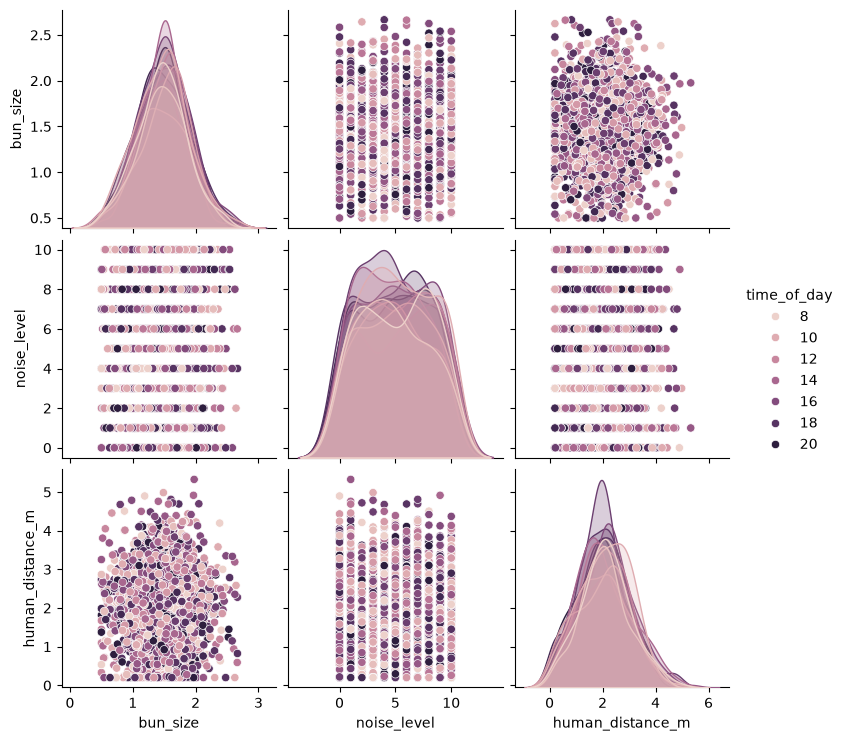

In [15]:
sns.pairplot(specific, hue='time_of_day')

In [13]:
#Grouping time_of_day into sections, used suggestion from copilot
sections = pd.cut(train_df["time_of_day"],
                  bins = [8, 12, 15, 18, 21],
                  labels = ["Morning", "Noon", "Afternoon", "Evening"],
                  right = False
)
specific2 = train_df[["distance_to_pigeons_m", "crumbs_on_ground", "human_distance_m", "feeding_spot_popularity"]].copy()
specific2["time_sections"] = sections
grouped_spec2 = specific2.groupby("time_sections")
grouped_spec2.describe().transpose()

time_sections                     Morning        Noon   Afternoon     Evening
distance_to_pigeons_m   count  590.000000  445.000000  482.000000  483.000000
                        mean     4.135330    4.073276    3.944112    4.028295
                        std      1.924307    1.952463    1.878624    1.932922
                        min      0.500000    0.500000    0.500000    0.500000
                        25%      2.763764    2.643300    2.547768    2.681083
                        50%      4.120121    4.135940    3.904639    3.964804
                        75%      5.449663    5.438186    5.153207    5.229084
                        max     10.063525    9.690589   10.047563   10.177024
crumbs_on_ground        count  590.000000  445.000000  482.000000  483.000000
                        mean     3.110971    3.160426    3.259616    3.115015
                        std      1.831837    2.029701    1.878786    2.002921
                        min      0.000000    0.000000    0.000000    0.000000
                        25%      1.743720    1.662553    1.813175    1.658339
                        50%      3.152239    3.041505    3.102388    3.153994
                        75%      4.333941    4.638938    4.652273    4.418395
                        max      8.846916    8.737538    8.346152    9.404652
human_distance_m        count  590.000000  445.000000  482.000000  483.000000
                        mean     2.072680    2.027440    2.055048    1.964231
                        std      0.966132    0.958998    0.965096    0.929344
                        min      0.200000    0.200000    0.200000    0.200000
                        25%      1.405581    1.332754    1.361692    1.335746
                        50%      2.087538    1.944092    2.033270    1.971320
                        75%      2.693194    2.679993    2.654492    2.562057
                        max      4.985593    4.916203    5.327472    4.691575
feeding_spot_popularity count  590.000000  445.000000  482.000000  483.000000
                        mean     5.004667    4.943894    4.949271    4.860299
                        std      2.466135    2.315520    2.368272    2.394516
                        min      0.000000    0.000000    0.000000    0.000000
                        25%      3.223706    3.382309    3.215930    3.170294
                        50%      5.036633    4.913538    4.953037    4.842230
                        75%      6.759191    6.472075    6.623682    6.568704
                        max     10.000000   10.000000   10.000000   10.000000

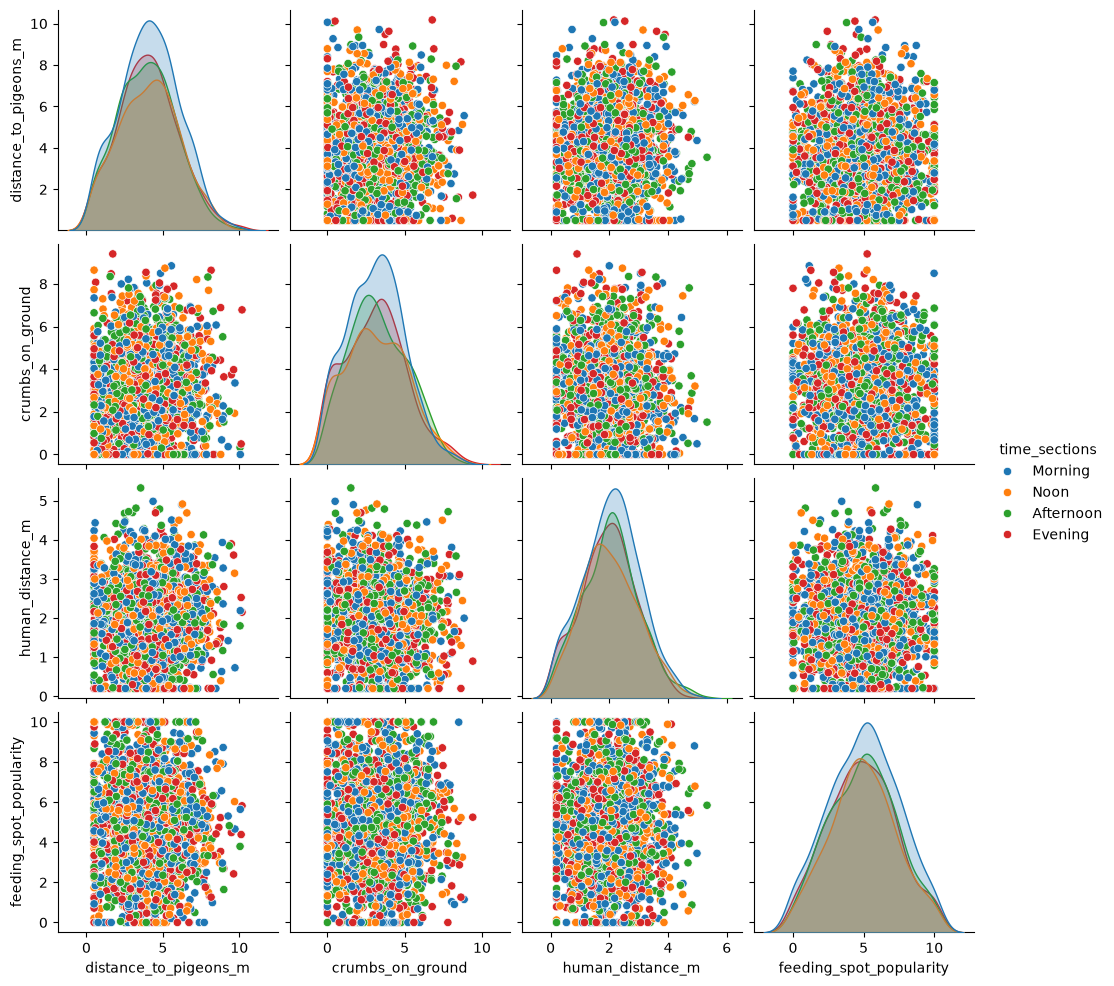

In [14]:
sns.pairplot(specific2, hue='time_sections')